# Figure 2 A — pre- vs post-task sleep d2

A schematic (presleep → task → postsleep) above full-window d2 on non-overlapping windows. The ripple-excised version is Supplementary Fig 4b.

Each panel is saved to `../figure_output/<Fig>/`.

In [1]:
# Data: ../csv/Fig2_A_prepost/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'Fig2_A_prepost'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import final_figs as F                     # print styles, saving, stars

## Fig 2A (top) — schematic: presleep → task → postsleep

A hand-drawn schematic (`../csv/Fig2_A_prepost/assets/fig2a_prepost_schematic_source.png`), its labels set as text: "Presleep", "Task", "Postsleep".

saved figure_output\Fig2\Fig2_A_schematic_prepost_task.svg / .png


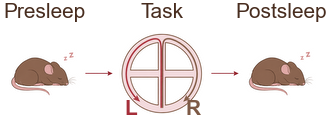

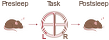

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Presleep -> task -> postsleep schematic. Drawn-in labels are replaced with text in the figure font, in one row
# above the drawing; the drawn "L" / "R" likewise. The five drawn pieces are cut out and centred on the maze's
# midline.
# ---- data (../csv) ----
SRC = CSV / "assets" / "fig2a_prepost_schematic_source.png"
# ---- the same from the recordings, with analysis_scripts/: ----
# SRC = os.path.join(F.FINAL, "Fig2", "source", "fig2a_prepost_schematic_source.png")
src = mpimg.imread(SRC)[..., :3].copy()
bg = np.median(src.reshape(-1, 3), axis=0)
src[np.abs(src - bg).max(axis=2) < 0.035] = 1.0      # the drawing's off-white paper -> white, so the cut-out pieces
bg = np.ones(3)                                      # leave no faint rectangles on the white figure
for y0, y1, x0, x1 in ((516, 560, 862, 896), (516, 560, 1275, 1314)):      # drawn "L", "R" (outside the maze's circle)
    src[y0:y1, x0:x1] = bg
PIECES = {"mouse_pre": (250, 545, 90, 528), "arrow_1": (340, 381, 577, 767), "maze": (36, 570, 815, 1355),
          "arrow_2": (340, 381, 1406, 1597), "mouse_post": (250, 545, 1654, 2088)}     # (y0, y1, x0, x1), source px
X0, X1 = 80, 2100
H = 570 - 36                                           # canvas height = the maze's; its midline = the maze's
canvas = np.ones((H, X1 - X0, 3), float) * bg
for y0, y1, x0, x1 in PIECES.values():                 # each piece at its own x, centred on the maze's midline
    top = int(round((H - (y1 - y0)) / 2))
    canvas[top:top + (y1 - y0), x0 - X0:x1 - X0] = src[y0:y1, x0:x1]
dy = -36                                               # source row -> canvas row, for the maze (L / R)
LABELS = [("Presleep", 309), ("Task", 1085), ("Postsleep", 1871)]          # centres of the drawn pieces (source px)
LR = [("L", 879, 538, "#a52e39"), ("R", 1294, 538, "#7d5945")]             # the drawing's own colours
TEXT, FS, W_SLOT, GAP_MM, LAB_MM = "#472c1e", 5.0, 27.4, 1.0, 2.2          # label colour; pt; mm: between the letters a and b

F.final_style()


def draw(w):
    h = w * canvas.shape[0] / canvas.shape[1]
    tot = h + GAP_MM + LAB_MM
    fig = plt.figure(figsize=(w * F.MM, tot * F.MM))
    ax = fig.add_axes([0, 0, 1, h / tot])
    ax.imshow(canvas, extent=[X0, X1, H, 0], interpolation="lanczos")      # x in source px, y in canvas rows
    ax.set_xlim(X0, X1); ax.set_ylim(H, 0); ax.axis("off")
    for t, x in LABELS:                                # one row above the drawing, GAP_MM clear of the maze's top
        ax.text(x, -GAP_MM / h * H, t, ha="center", va="bottom", fontsize=FS, color=TEXT, clip_on=False)
    for t, x, y, c in LR:
        ax.text(x, y + dy, t, ha="center", va="center", fontsize=FS, color=c, fontweight="bold")
    return fig


w = 26.0                                              # the drawing's width; labels may stick out at the ends
for _ in range(4):                                    # size it so drawing + labels fit between the letters a and b
    fig = draw(w)
    fig.canvas.draw()
    tw = fig.get_tightbbox(fig.canvas.get_renderer()).width * 25.4
    if abs(tw - W_SLOT) < 0.05:
        break
    plt.close(fig)
    w *= W_SLOT / tw
png = F.save(fig, "Fig2_A_schematic_prepost_task")
F.show(png)

## Fig 2A — pre- vs post-task sleep d2, non-overlapping windows

d2 (2024 Euclidean, AR p = 20, 40 ms, full window), NREM, presleep vs post-task sleep (the mid-session sleep, which all 9 sessions have), per-session means of the non-overlapping windows (centres ≥ 30 s apart; 6 730 windows), drawn by the Fig 2a notebook of the first submission (`Previous_Rv1/figure_scripts/Fig2_A_FigS2_B_FigS3_A.ipynb`).

- Test: session-paired signed-rank test on session-level d2.

a: post vs pre, two-sided paired Wilcoxon signed-rank p = 0.0039; n = 9 sessions


saved figure_output\Fig2\Fig2_A_prepost_full_d2_nonoverlap.svg / .png


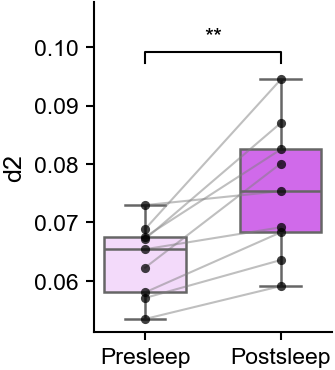

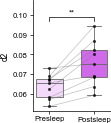

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ---- data (../csv) ----
TABLE = CSV / "fig2a_prepost_sessions_disjoint.csv"
# ---- the same from the recordings, with analysis_scripts/: ----
# TABLE = os.path.join(F.REPO, "data", "revision", "log", "fig2a_prepost_sessions_disjoint.csv")
# if not os.path.exists(TABLE):          # the per-session table the submitted notebook plots, on disjoint windows
#     F.rv1_table("Fig2_A_FigS2_B_FigS3_A",
#                 r'save_path = r"../figure_output\fig2A_S2B_pre_vs_postsleep_perfile_paired.svg"', "summary_df", TABLE)
S = pd.read_csv(TABLE)
P = S.pivot(index="animal_day", columns="epoch2", values="d2").dropna()[["Presleep", "Postsleep"]]
dlt = P.Postsleep - P.Presleep
p = stats.wilcoxon(P.Postsleep, P.Presleep).pvalue
print(f"a: post vs pre, two-sided paired Wilcoxon signed-rank p = {p:.2g}; n = {len(P)} sessions")

F.final_style()
order, pal = ["Presleep", "Postsleep"], {"Presleep": "#f6d5ff", "Postsleep": "#dd55ff"}    # the notebook's palette
fig, ax = plt.subplots(figsize=(30 * F.MM, 33 * F.MM), layout="constrained")
sns.boxplot(data=S, x="epoch2", y="d2", order=order, hue="epoch2", hue_order=order, palette=pal, legend=False,
            showfliers=False, width=0.6, linewidth=0.6, ax=ax, zorder=2)
sns.stripplot(data=S, x="epoch2", y="d2", order=order, color="k", jitter=False, alpha=0.75, size=2.2, ax=ax, zorder=3)
for _, r in P.iterrows():                                                     # the notebook's paired lines
    ax.plot([0, 1], [r.Presleep, r.Postsleep], color="gray", alpha=0.5, lw=0.5, zorder=2)
top = S.d2.max()
ax.plot([0, 0, 1, 1], [top * 1.03, top * 1.05, top * 1.05, top * 1.03], color="k", lw=0.5)
ax.text(0.5, top * 1.06, f"{int((dlt > 0).sum())}/{len(P)} ↑ {'**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'}",
        ha="center", va="bottom", fontsize=5.5)                               # session-paired signed-rank
ax.set_ylim(top=top * 1.14)
ax.set_xlabel(""); ax.set_ylabel("d2")
F.settle(fig)
F.drop_counts(fig)                          # formal panel: no k/n; counts in the legend
png = F.save(fig, "Fig2_A_prepost_full_d2_nonoverlap")
F.show(png)